In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
!C:\Users\HP\AppData\Roaming\jupyterlab-desktop\jlab_server\python.exe -m pip install openpyxl


  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)


In [4]:
df = pd.read_excel(r"C:\Users\HP\Downloads\HousePricePrediction.xlsx")
print(df.head(5))

   Id  MSSubClass MSZoning  LotArea LotConfig BldgType  OverallCond  \
0   0          60       RL     8450    Inside     1Fam            5   
1   1          20       RL     9600       FR2     1Fam            8   
2   2          60       RL    11250    Inside     1Fam            5   
3   3          70       RL     9550    Corner     1Fam            5   
4   4          60       RL    14260       FR2     1Fam            5   

   YearBuilt  YearRemodAdd Exterior1st  BsmtFinSF2  TotalBsmtSF  SalePrice  
0       2003          2003     VinylSd         0.0        856.0   208500.0  
1       1976          1976     MetalSd         0.0       1262.0   181500.0  
2       2001          2002     VinylSd         0.0        920.0   223500.0  
3       1915          1970     Wd Sdng         0.0        756.0   140000.0  
4       2000          2000     VinylSd         0.0       1145.0   250000.0  


In [7]:
display(df.info())
display(df.columns)
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 296.6+ KB


None

Index(['Id', 'MSSubClass', 'MSZoning', 'LotArea', 'LotConfig', 'BldgType',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'Exterior1st', 'BsmtFinSF2',
       'TotalBsmtSF', 'SalePrice'],
      dtype='object')

(2919, 13)


In [11]:
print(df.dtypes.value_counts())
print()

object_cols = df.select_dtypes(include=['object']).columns
print('Object: ', len(object_cols))

int_cols = df.select_dtypes(include=['int64']).columns
print('Integer: ', len(int_cols))

float_cols = df.select_dtypes(include=['float64']).columns
print('Float: ', len(float_cols))

int64      6
object     4
float64    3
Name: count, dtype: int64

Object:  4
Integer:  6
Float:  3


Heatmap saved as correlation_heatmap.png


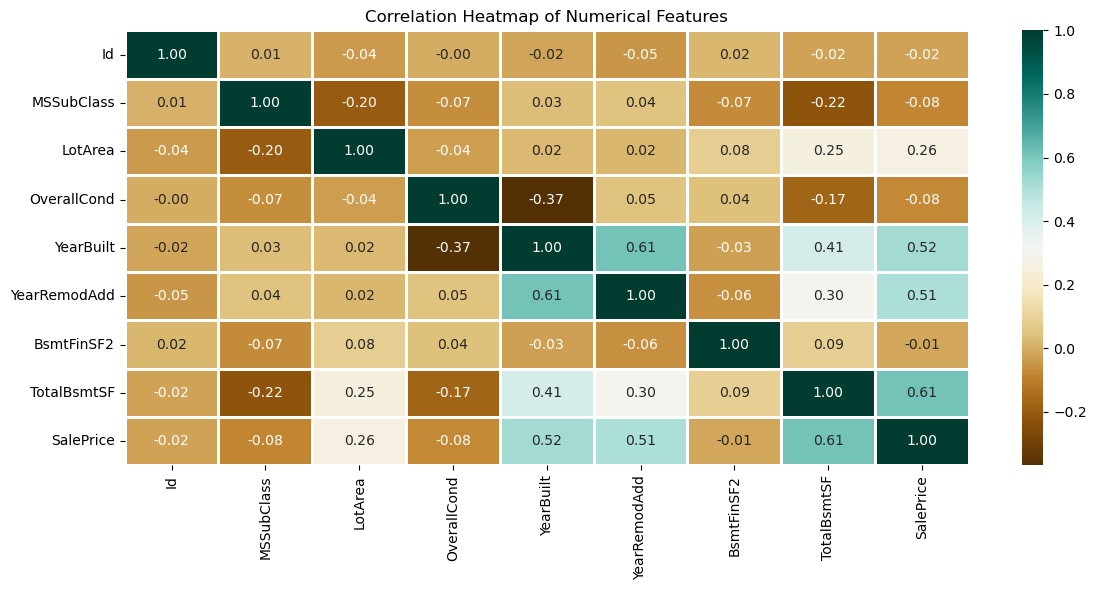

In [14]:
num_data = df.select_dtypes(include=['int64', 'float64'])
plt.figure(figsize=(12, 6))
sns.heatmap(num_data.corr(), cmap='BrBG', fmt='.2f', linewidths=2, annot=True)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
print("Heatmap saved as correlation_heatmap.png")

<Axes: title={'center': 'No. Unique values of Categorical Features'}, xlabel='None'>

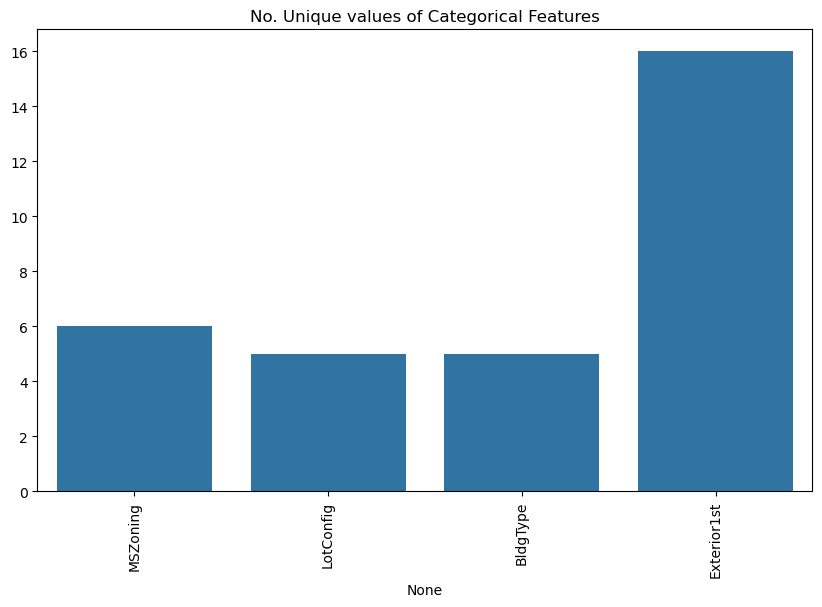

In [16]:
unique_values = []
for col in object_cols:
    unique_values.append(df[col].unique().size)
plt.figure(figsize=(10, 6))
plt.title('No. Unique values of Categorical Features')
plt.xticks(rotation=90)
sns.barplot(x=object_cols, y=unique_values)

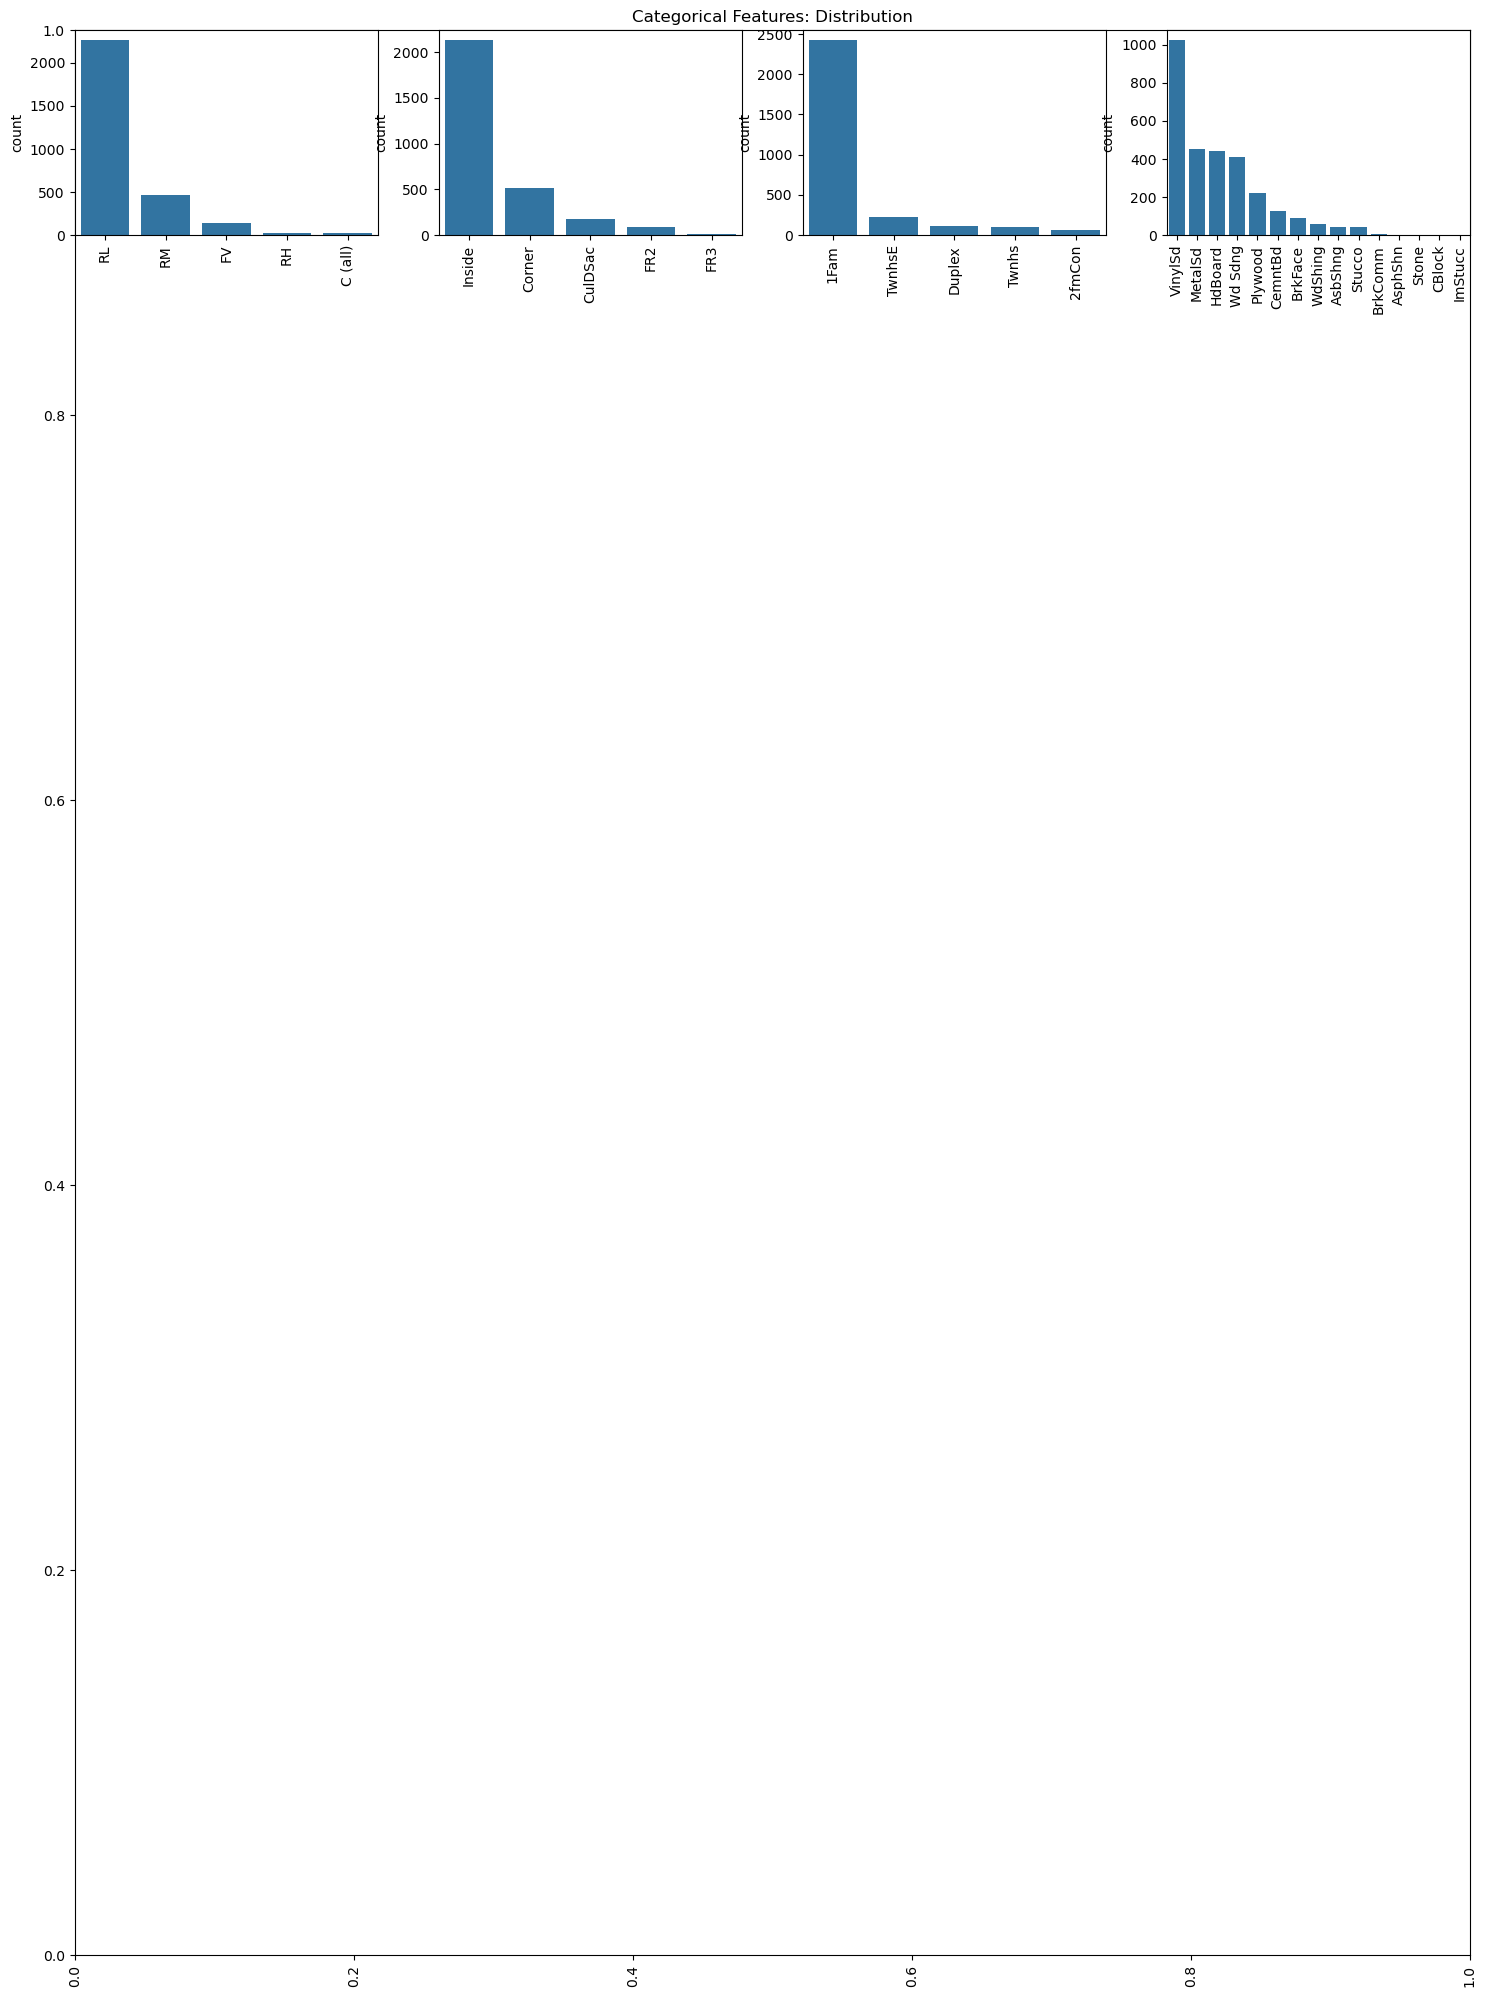

In [26]:
plt.figure(figsize=(18, 25))
plt.title('Categorical Features: Distribution')
plt.xticks(rotation=90)
index = 1

for col in object_cols:
    y = df[col].value_counts()
    plt.subplot(8, 4, index)
    plt.xticks(rotation=90)
    sns.barplot(x=list(y.index), y=y)
    index += 1

df.drop(['Id'], axis=1, inplace=True)

In [30]:
df['SalePrice'] = df['SalePrice'].fillna(df['SalePrice'].mean())
new_df = df.dropna()

In [31]:
df.isnull().sum()

MSSubClass      0
MSZoning        4
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     1
BsmtFinSF2      1
TotalBsmtSF     1
SalePrice       0
dtype: int64

In [32]:
# One hot Encoding is the best way to convert categorical data into binary vectors 
import sklearn
from sklearn.preprocessing import OneHotEncoder

s = new_df.select_dtypes(include=['object']).columns
print(s)
print(len(s))

Index(['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st'], dtype='object')
4


In [34]:
# df_final = pd.get_dummies(new_df, drop_first=False)

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded = pd.DataFrame(
    encoder.fit_transform(new_df[object_cols]),
    index= new_df.index,
    columns = encoder.get_feature_names_out()
)
df_final = pd.concat([new_df.drop(object_cols, axis=1), encoded], axis=1)

In [38]:
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

X = df_final.drop('SalePrice', axis=1)
y = df_final['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler() # SVR requires scaling
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_SVR = svm.SVR(kernel='rbf')   # default kernel is RBF
model_SVR.fit(X_train_scaled, y_train)

y_pred = model_SVR.predict(X_test_scaled)

mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = model_SVR.score(X_test_scaled, y_test)

print("MAPE:", mape)
print("R² Score:", r2)

MAPE: 0.20686482515498694
R² Score: -0.000937516517983461


In [42]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error

model_RFR = RandomForestRegressor(n_estimators=10, random_state=42)
model_RFR.fit(X_train, y_train)

y_pred = model_RFR.predict(X_test)

print("MAPE:", mean_absolute_percentage_error(y_test, y_pred))
print("R² Score:", model_RFR.score(X_test, y_test))

MAPE: 0.2078625534779545
R² Score: 0.32112977682934307


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error

model_LR = LinearRegression()
model_LR.fit(X_train, y_train)

Y_pred = model_LR.predict(X_test)

print(mean_absolute_percentage_error(y_test, Y_pred))
print(model_LR.score(X_test, y_test))

0.20023501039962308
0.3468812454588831
